<a href="https://colab.research.google.com/github/Leena2403/Brain_Network_Development_fMRI/blob/main/Brain_Network_Development_fMRI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Question: Do the brain’s functional networks reorganize between childhood (3–12 years) and adulthood?**


---

**Hypotheses:**

H1: The pattern of connections between brain regions is different enough to tell children from adults.

H2: With development, brain organization shifts from mostly local connections to more distributed ones: regions within the same network become more tightly linked, and connections across distant networks get more specialized. (Based on Fair et al., 2009, PLoS Comp Bio; Dosenbach et al., 2010, Science.)

H3: These differences are not just explained by children moving more in the scanner.


---

Data: Richardson et al., 2018, Nature Communications: 155 participants watching the short film Partly Cloudy; preprocessed with fMRIPrep.

In [1]:
!pip install -q nilearn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nilearn import datasets, image, plotting

sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(42)
TR = 2.0

In [27]:
# data = datasets.fetch_development_fmri(n_subjects=None)

# pheno = pd.DataFrame(data.phenotypic)
# print(data.keys())
# print(pheno.columns.tolist())
# pheno.head()

Shape (x, y, z, time): (50, 59, 50, 168)
Voxel size + TR (s): (np.float32(4.0), np.float32(4.0), np.float32(4.0), np.float32(1.0))


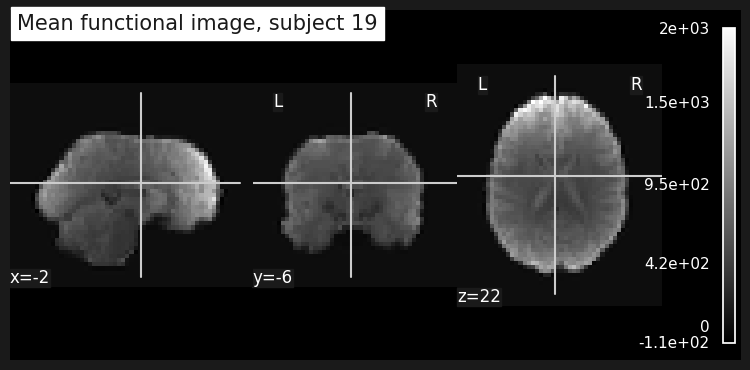

In [4]:
img = image.load_img(data.func[19])
print("Shape (x, y, z, time):", img.shape)
print("Voxel size + TR (s):", img.header.get_zooms())

plotting.plot_epi(image.mean_img(img), title="Mean functional image, subject 19")
plt.show()

Each scan is 50×59×50 voxels (4 mm) × 168 volumes. TR = 2 s (from the original paper), so about 5.6 min per person. The mean image looks properly aligned to standard (MNI) space, with no visible problems.

Shape (x, y, z, time): (50, 59, 50, 168)
Voxel size + TR (s): (np.float32(4.0), np.float32(4.0), np.float32(4.0), np.float32(1.0))


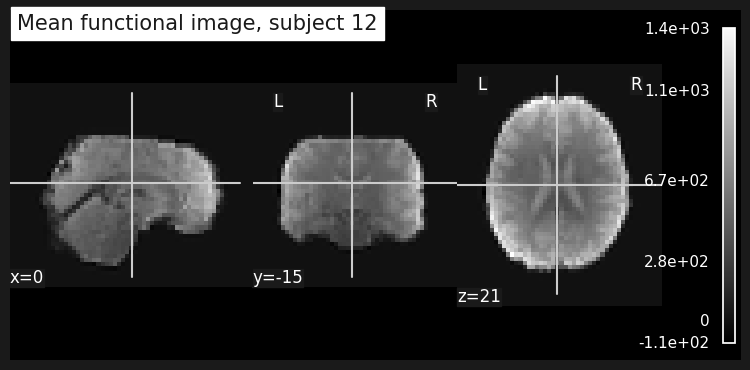

In [5]:
img = image.load_img(data.func[12])
print("Shape (x, y, z, time):", img.shape)
print("Voxel size + TR (s):", img.header.get_zooms())

plotting.plot_epi(image.mean_img(img), title="Mean functional image, subject 12")
plt.show()

Child_Adult
child    122
adult     33
Name: count, dtype: int64
             count       mean       std        min       25%    50%      75%  \
Child_Adult                                                                    
adult         33.0  24.772727  5.308521  18.000000  21.00000  23.00  28.0000   
child        122.0   6.709461  2.330938   3.518138   4.89521   5.98   8.3975   

              max  
Child_Adult        
adult        39.0  
child        12.3  


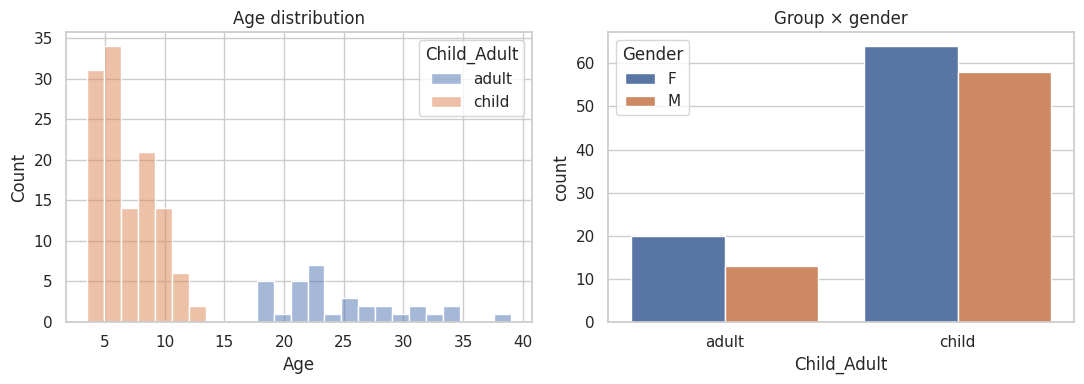

In [6]:
print(pheno["Child_Adult"].value_counts())
print(pheno.groupby("Child_Adult")["Age"].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=pheno, x="Age", hue="Child_Adult", bins=25, ax=axes[0])
axes[0].set_title("Age distribution")
sns.countplot(data=pheno, x="Child_Adult", hue="Gender", ax=axes[1])
axes[1].set_title("Group × gender")
plt.tight_layout(); plt.show()

**Head-motion check**

In [7]:
mean_fd, high_motion_frac = [], []
for conf_file in data.confounds:
    conf = pd.read_csv(conf_file, sep="\t")
    fd = conf["framewise_displacement"].fillna(0)
    mean_fd.append(fd.mean())
    high_motion_frac.append((fd > 0.5).mean())

pheno["mean_fd"] = mean_fd
pheno["high_motion_frac"] = high_motion_frac
pheno[["participant_id", "Age", "Child_Adult", "mean_fd", "high_motion_frac"]].head()

,participant_id,Age,Child_Adult,mean_fd,high_motion_frac
122,sub-pixar123,27.06,adult,0.159037,0.005952
123,sub-pixar124,33.44,adult,0.528821,0.375000
124,sub-pixar125,31.00,adult,0.148315,0.047619
125,sub-pixar126,19.00,adult,0.189773,0.017857
126,sub-pixar127,23.00,adult,0.196257,0.035714


Why FD? Framewise displacement (Power et al., 2012) summarizes, in one number per time point, how much the head moved between consecutive volumes (in mm). 0.5 mm is a commonly used threshold for a “big” movement.

**Do children move more?**

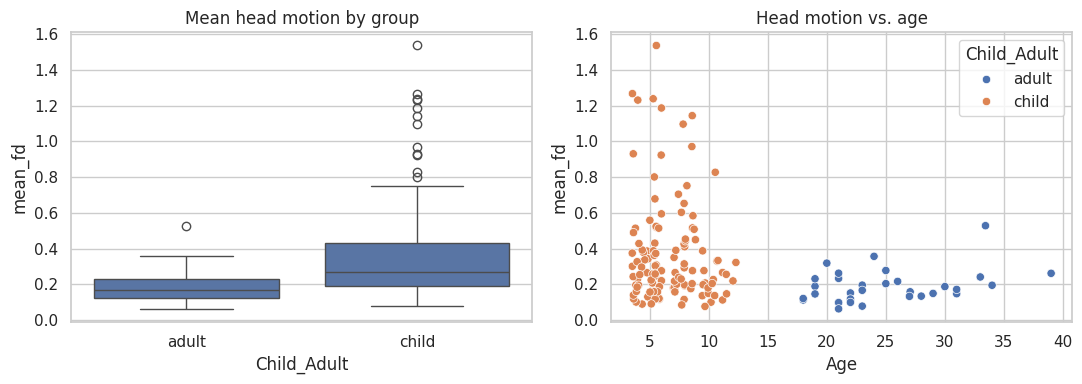

MannwhitneyuResult(statistic=np.float64(3035.0), pvalue=np.float64(8.003666719091488e-06))
Spearman (age vs FD): SignificanceResult(statistic=np.float64(-0.28751810826244667), pvalue=np.float64(0.00028618027529550447))


In [8]:
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=pheno, x="Child_Adult", y="mean_fd", ax=axes[0])
axes[0].set_title("Mean head motion by group")
sns.scatterplot(data=pheno, x="Age", y="mean_fd", hue="Child_Adult", ax=axes[1])
axes[1].set_title("Head motion vs. age")
plt.tight_layout(); plt.show()

kids = pheno.loc[pheno.Child_Adult == "child", "mean_fd"]
adults = pheno.loc[pheno.Child_Adult == "adult", "mean_fd"]
print(stats.mannwhitneyu(kids, adults))
print("Spearman (age vs FD):", stats.spearmanr(pheno.Age, pheno.mean_fd))

Head motion was measured with mean framewise displacement (FD; Power et al., 2012) and the share of volumes with FD > 0.5 mm. Motion is the main confound in developmental fMRI because it creates false correlations between brain regions.


---

Children moved significantly more than adults (Mann-Whitney U = 3035 of 4026 child–adult pairs, about 75% vs. 50% expected by chance; p = 8.0 × 10⁻⁶). Motion decreased with age (Spearman ρ = −0.29, p = 0.0003). This confirms the known problem in developmental fMRI: age and motion are linked, so motion must be controlled for to avoid false findings.

Why Mann-Whitney / Spearman? FD values are skewed (a few people move a lot), so rank-based tests are safer than t-tests or Pearson correlation.

In [9]:
FD_THRESHOLD = 0.5      # mm, mean FD
FRAC_THRESHOLD = 0.2    # max 20% of volumes with FD > 0.5 mm

pheno["exclude"] = (pheno.mean_fd > FD_THRESHOLD) | (pheno.high_motion_frac > FRAC_THRESHOLD)
print(pheno.groupby("Child_Adult")["exclude"].sum(), "excluded per group")

keep_idx = np.where(~pheno["exclude"])[0]
func_files = [data.func[i] for i in keep_idx]
conf_files = [data.confounds[i] for i in keep_idx]
pheno_clean = pheno.iloc[keep_idx].reset_index(drop=True)
print("Final sample:", pheno_clean.Child_Adult.value_counts().to_dict())

Child_Adult
adult     1
child    34
Name: exclude, dtype: int64 excluded per group
Final sample: {'child': 88, 'adult': 32}


Why decide these rules now? You set the exclusion rules before looking at any results, so you can’t be accused of tuning them to get a nicer answer. Write the excluded count per group in your notebook: if mostly young children are dropped, that’s a limitation worth stating.


---

Applying the rule set beforehand (mean FD > 0.5 mm or more than 20% of volumes with FD > 0.5 mm) excluded 34/122 children (28%) and 1/33 adults (3%). Final sample: 88 children and 32 adults (n = 120). The uneven exclusion is a limitation: the kept children may be calmer than typical children of their age.

Which children were excluded?

In [10]:
excl_kids = pheno[(pheno.Child_Adult == "child") & (pheno.exclude)]
kept_kids = pheno[(pheno.Child_Adult == "child") & (~pheno.exclude)]
print("Excluded children age:", excl_kids.Age.describe()[["mean", "min", "max"]].round(2).to_dict())
print("Kept children age:   ", kept_kids.Age.describe()[["mean", "min", "max"]].round(2).to_dict())
print(stats.mannwhitneyu(excl_kids.Age, kept_kids.Age))

Excluded children age: {'mean': 6.56, 'min': 3.53, 'max': 10.55}
Kept children age:    {'mean': 6.77, 'min': 3.52, 'max': 12.3}
MannwhitneyuResult(statistic=np.float64(1519.5), pvalue=np.float64(0.8955049063485728))


If mostly the youngest children were excluded, our “child” group becomes older than the original sample. We need to know that, and report it.

**Is there still a motion difference after exclusion?**

In [11]:
kids_c = pheno_clean.loc[pheno_clean.Child_Adult == "child", "mean_fd"]
adults_c = pheno_clean.loc[pheno_clean.Child_Adult == "adult", "mean_fd"]
print("After exclusion:", stats.mannwhitneyu(kids_c, adults_c))
print("Median FD  children: %.3f | adults: %.3f" % (kids_c.median(), adults_c.median()))

After exclusion: MannwhitneyuResult(statistic=np.float64(1927.0), pvalue=np.float64(0.0020908100232093357))
Median FD  children: 0.220 | adults: 0.163


If the difference is still significant, we must control for motion on Day 3 (Section 9). Either way, you’ll be able to answer a professor who asks “Isn’t this just motion?”

**Brain scans → brain-region signals**

In [17]:
import os
from nilearn.maskers import NiftiMapsMasker
from nilearn.connectome import ConnectivityMeasure
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

[fetch_atlas_msdl] Dataset created in /root/nilearn_data/msdl_atlas

[fetch_atlas_msdl] Downloading data from https://team.inria.fr/parietal/files/2015/01/MSDL_rois.zip ...

[fetch_atlas_msdl]  ...done. (1 seconds, 0 min)

[fetch_atlas_msdl] Extracting data from /root/nilearn_data/msdl_atlas/e79625f201e60c733df1b1ddd19a0427/MSDL_rois.zip...

[fetch_atlas_msdl] .. done.

39 regions in 17 networks

Language    5
DMN         4
R V Att     4
L V Att     3
Vis Sec     3
Salience    3
Cing-Ins    3
Aud         2
D Att       2
Temporal    2
Ant IPS     2
Striate     1
Occ post    1
Motor       1
Basal       1
Cereb       1
Dors PCC    1


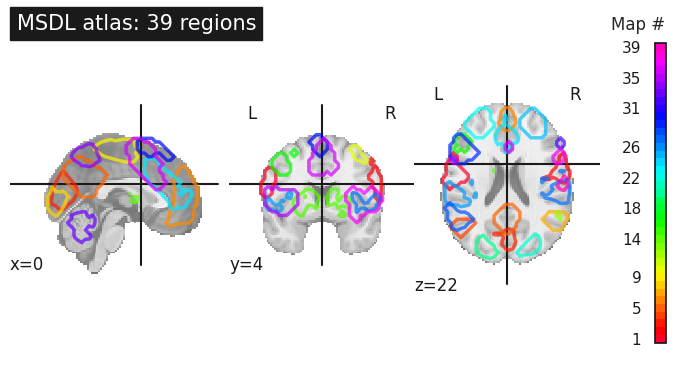

In [12]:
msdl = datasets.fetch_atlas_msdl()
labels   = np.array(msdl.labels)          # region names, e.g. "L DMN"
networks = np.array(msdl.networks)        # which network each region belongs to
coords   = np.array(msdl.region_coords)   # (x, y, z) position of each region, for brain plots

print(f"{len(labels)} regions in {len(set(networks))} networks\n")
print(pd.Series(networks).value_counts().to_string())

plotting.plot_prob_atlas(msdl.maps, title="MSDL atlas: 39 regions")
plt.show()

Why MSDL? 39 regions grouped into known networks (default mode, attention, visual, motor, language, salience…), so results can be described as networks changing. It was designed for connectivity analysis (Varoquaux et al., 2011), and nilearn's own tutorial uses it on this dataset. A finer atlas such as Schaefer-400 would give far more features than our 120 participants.

**Noise signals to remove**

In [20]:
def load_confounds(conf_file):
    """Pick the noise signals to remove from one participant's data."""
    conf = pd.read_csv(conf_file, sep="\t")
    motion  = ["trans_x", "trans_y", "trans_z", "rot_x", "rot_y", "rot_z"]   # head movement
    tissue  = ["white_matter", "csf"]                                       # non-neural signal
    compcor = [c for c in conf.columns if c.startswith("a_comp_cor")][:5]   # main noise patterns
    cols = [c for c in motion + tissue + compcor if c in conf.columns]
    return conf[cols].fillna(0).values   # first row has NaNs (no previous volume) → 0

example = load_confounds(conf_files[0])
print("Confounds per participant:", example.shape, "(time points × noise signals)")

Confounds per participant: (168, 13) (time points × noise signals)


Motion creates fake signal changes. White matter and CSF have no neurons, so their signal is breathing, heartbeat and scanner drift. aCompCor (Behzadi et al., 2007) captures the main noise patterns from those tissues. We don't remove the global (whole-brain) signal, because that can create artificial negative correlations.

In [21]:
import os

In [22]:
from google.colab import drive
drive.mount("/content/drive")

SAVE_PATH = "/content/drive/MyDrive/brain_fmri/time_series_msdl.npz"
os.makedirs(os.path.dirname(SAVE_PATH), exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
masker = NiftiMapsMasker(
    maps_img=msdl.maps,
    standardize="zscore_sample",   # each region: mean 0, std 1
    detrend=True,                  # remove slow linear drift
    high_pass=0.01,                # remove very slow drift (< 0.01 Hz)
    low_pass=0.1,                  # remove fast noise (> 0.1 Hz)
    t_r=2,                        # 2 s between volumes
    verbose=0,
)

ids = pheno_clean["participant_id"].values

if os.path.exists(SAVE_PATH):
    saved = np.load(SAVE_PATH, allow_pickle=True)
    assert list(saved["ids"]) == list(ids), "Saved file is for a different sample: delete it and rerun"
    time_series = list(saved["time_series"])
    print("Loaded saved time series from Drive")
else:
    time_series = []
    for i, (func, conf) in enumerate(zip(func_files, conf_files)):
        ts = masker.fit_transform(func, confounds=load_confounds(conf))
        time_series.append(ts)
        if (i + 1) % 20 == 0:
            print(f"  done {i + 1}/{len(func_files)}")
    np.savez_compressed(SAVE_PATH, time_series=np.stack(time_series), ids=ids)
    print("Extracted and saved to Drive")

print(f"{len(time_series)} participants, each {time_series[0].shape} (time points × regions)")

  done 20/120
  done 40/120
  done 60/120
  done 80/120
  done 100/120
  done 120/120
Extracted and saved to Drive
120 participants, each (168, 39) (time points × regions)


Why 0.01–0.1 Hz? Connectivity-related brain fluctuations are slow. Below 0.01 Hz is mostly scanner drift; above 0.1 Hz is mostly breathing and heartbeat noise.

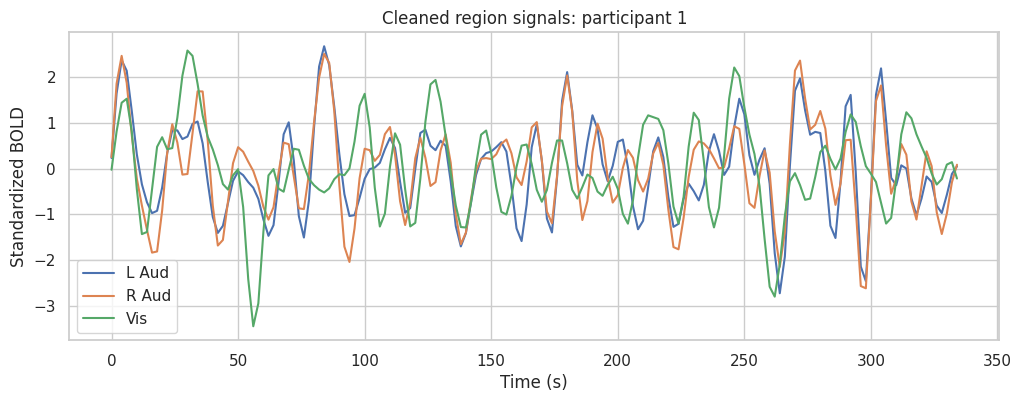

In [26]:
fig, ax = plt.subplots(figsize=(12, 4))
t = np.arange(time_series[0].shape[0]) * TR
for r in [0, 1, 20]:
    ax.plot(t, time_series[0][:, r], label=labels[r])
ax.set(xlabel="Time (s)", ylabel="Standardized BOLD", title="Cleaned region signals: participant 1")
ax.legend(); plt.show()

slow waves around 0. Regions whose lines rise and fall together are "functionally connected." Section 5 measures that for every pair of regions.

**Section 5: Connectivity matrices: how do children and adults differ?**

What we're doing: for each person, we correlate every pair of regions: 39 × 38 / 2 = 741 connections. That's each person's brain-wiring fingerprint. Then we compare the average child with the average adult.

Compute correlation matrices

In [28]:
is_child = (pheno_clean["Child_Adult"] == "child").values
y = (~is_child).astype(int)                     # 0 = child, 1 = adult
order = np.argsort(networks, kind="stable")     # sort regions by network so blocks are visible

corr_measure = ConnectivityMeasure(kind="correlation", standardize="zscore_sample")
corr_mats = corr_measure.fit_transform(time_series)          # (120, 39, 39)

# Fisher z-transform before averaging (correlations can't be averaged directly)
z_mats = np.arctanh(np.clip(corr_mats, -0.999, 0.999))
mean_child = np.tanh(z_mats[is_child].mean(axis=0))
mean_adult = np.tanh(z_mats[~is_child].mean(axis=0))
print("Matrices:", corr_mats.shape)

Matrices: (120, 39, 39)


Why Fisher z? Correlations are bounded at ±1, so averaging them directly is biased. arctanh stretches them onto an unbounded scale where averaging is valid; tanh converts back.

Child vs. adult matrices side by side

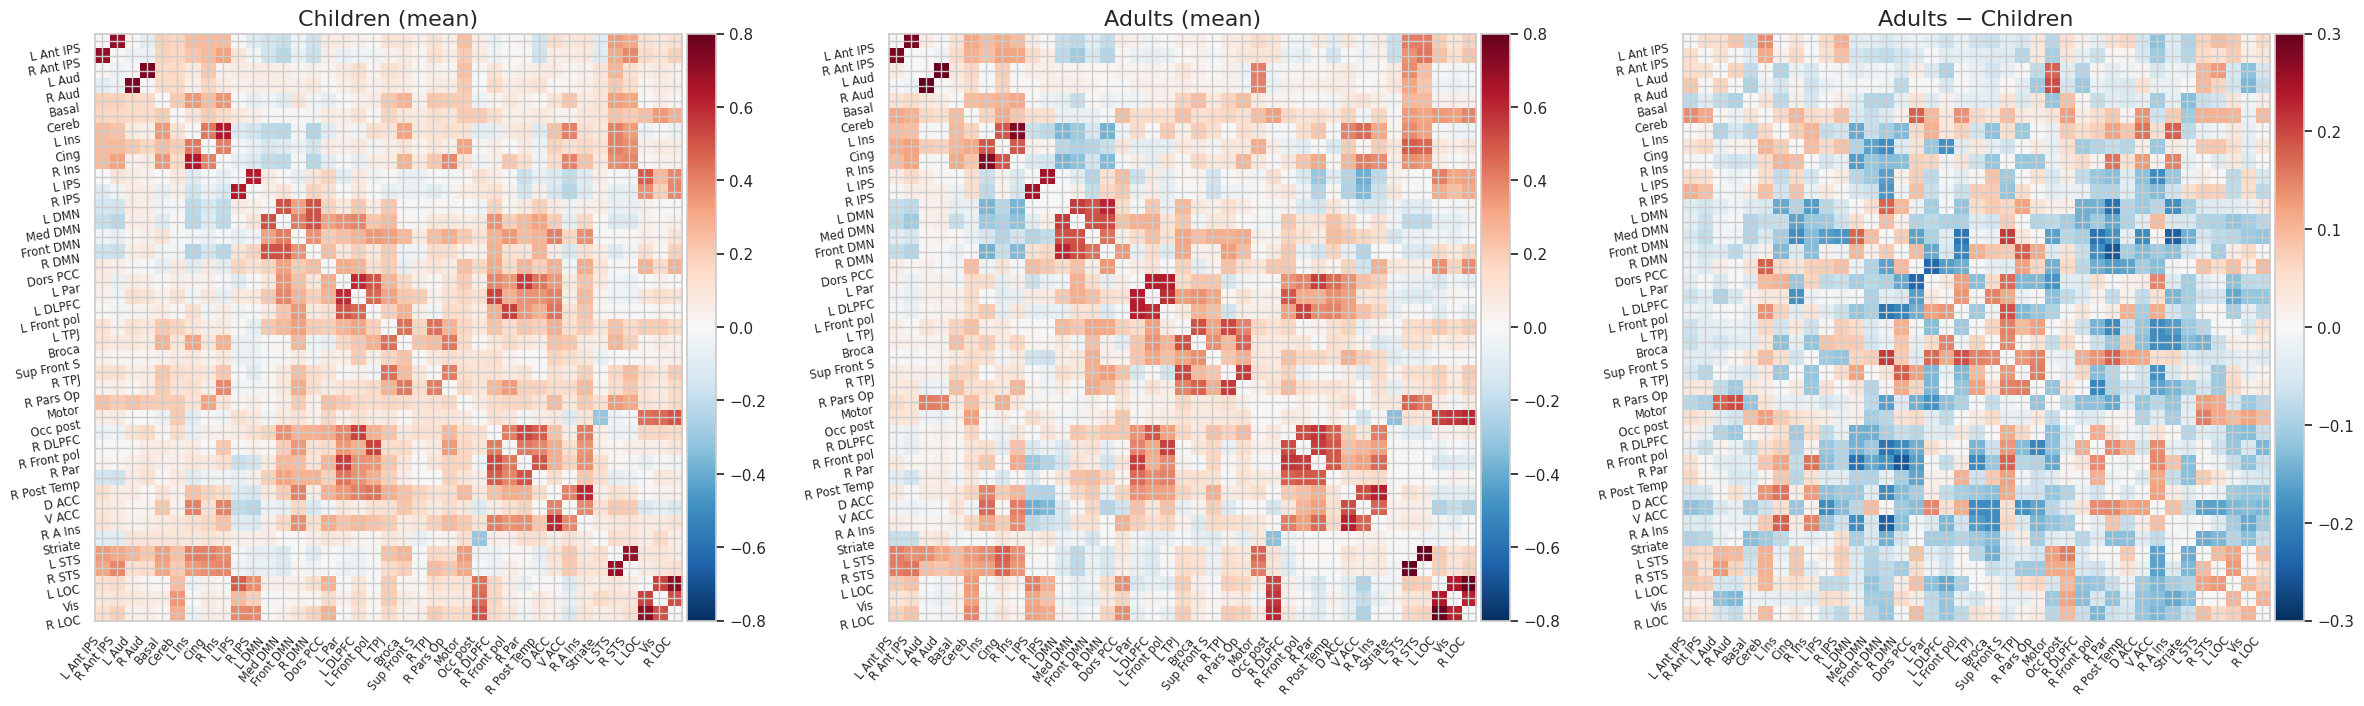

In [29]:
def show_matrix(mat, title, vmax, ax):
    m = mat.copy()
    np.fill_diagonal(m, 0)   # hide self-connections (always 1)
    plotting.plot_matrix(m[np.ix_(order, order)], labels=list(labels[order]),
                         vmin=-vmax, vmax=vmax, axes=ax, title=title, colorbar=True)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
show_matrix(mean_child, "Children (mean)", 0.8, axes[0])
show_matrix(mean_adult, "Adults (mean)", 0.8, axes[1])
show_matrix(mean_adult - mean_child, "Adults − Children", 0.3, axes[2])
plt.tight_layout(); plt.show()

Each square is one pair of regions. Red means the two regions rise and fall together; blue means they move in opposite directions. Squares along the diagonal are connections within the same network. In the third panel, red means stronger in adults and blue means stronger in children.

Zoom out to networks

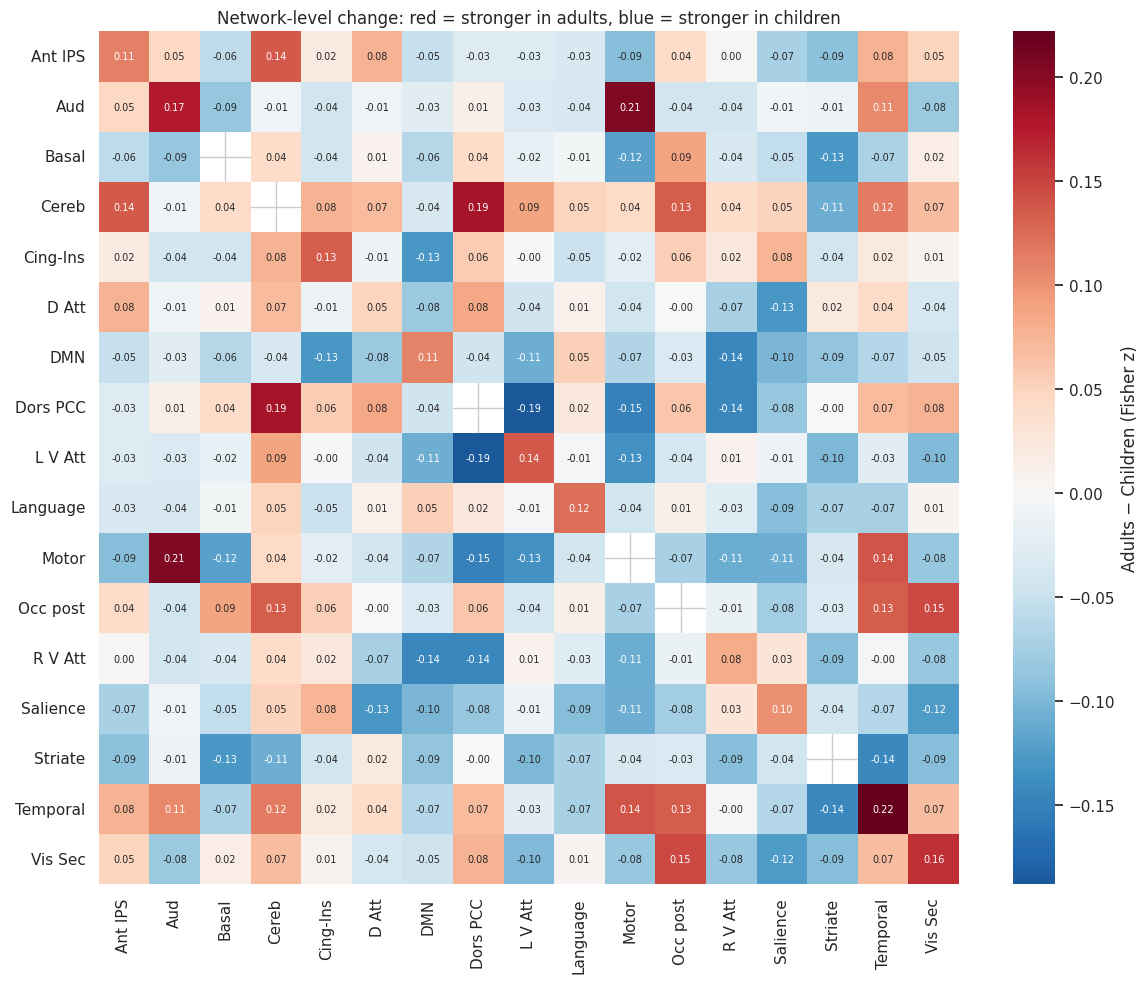

In [30]:
net_names = list(dict.fromkeys(networks[order]))   # network names in plot order

def network_summary(mat):
    """Average connectivity within and between each pair of networks."""
    out = pd.DataFrame(index=net_names, columns=net_names, dtype=float)
    for a in net_names:
        for b in net_names:
            ia, ib = np.where(networks == a)[0], np.where(networks == b)[0]
            block = mat[np.ix_(ia, ib)]
            if a == b:   # within a network: drop self-connections
                block = block[~np.eye(len(ia), dtype=bool)]
            out.loc[a, b] = block.mean() if block.size else np.nan
    return out

net_diff = network_summary(z_mats[~is_child].mean(0)) - network_summary(z_mats[is_child].mean(0))

plt.figure(figsize=(12, 10))
sns.heatmap(net_diff, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"label": "Adults − Children (Fisher z)"})
plt.title("Network-level change: red = stronger in adults, blue = stronger in children")
plt.tight_layout(); plt.show()

Within- vs. between-network connectivity per person (first look at H2)

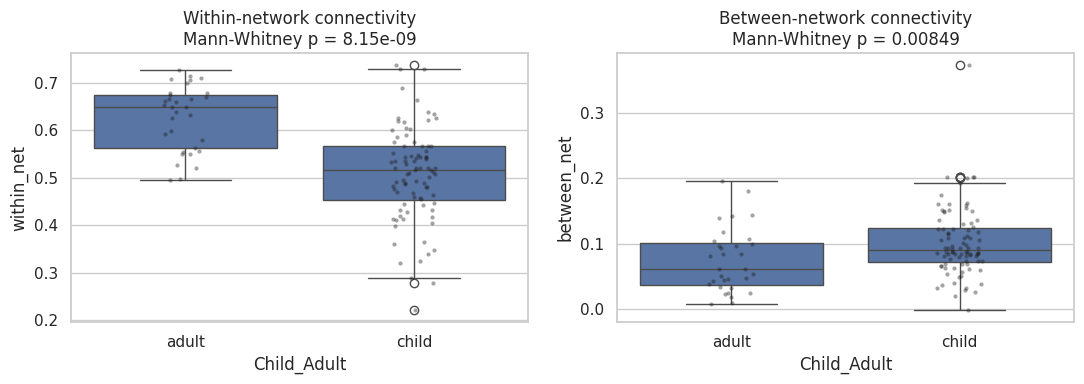

In [31]:
same_net = networks[:, None] == networks[None, :]
off_diag = ~np.eye(len(labels), dtype=bool)

pheno_clean["within_net"]  = z_mats[:, same_net & off_diag].mean(axis=1)
pheno_clean["between_net"] = z_mats[:, ~same_net].mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["within_net", "between_net"],
                          ["Within-network connectivity", "Between-network connectivity"]):
    sns.boxplot(data=pheno_clean, x="Child_Adult", y=col, ax=ax)
    sns.stripplot(data=pheno_clean, x="Child_Adult", y=col, ax=ax, color="k", alpha=0.4, size=3)
    p = stats.mannwhitneyu(pheno_clean.loc[is_child, col], pheno_clean.loc[~is_child, col]).pvalue
    ax.set_title(f"{title}\nMann-Whitney p = {p:.3g}")
plt.tight_layout(); plt.show()

Why? H2 predicts that with age, regions in the same network become more tightly linked (within ↑) and networks become more distinct (between ↓). Here each person becomes two numbers we can compare.

The biggest differences on a brain

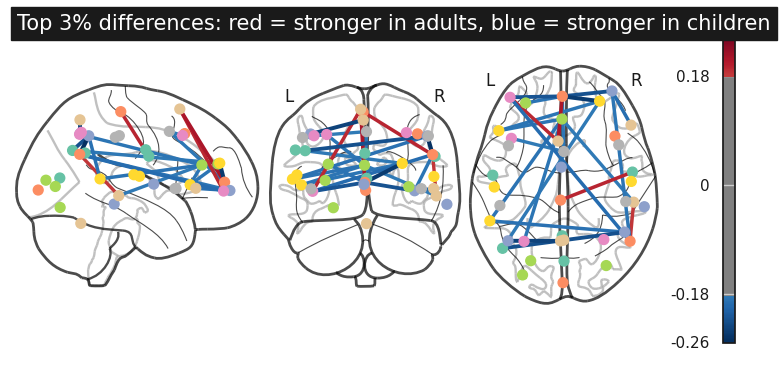

In [32]:
diff = mean_adult - mean_child
np.fill_diagonal(diff, 0)
plotting.plot_connectome(diff, coords, edge_threshold="97%", edge_cmap="RdBu_r",
                         title="Top 3% differences: red = stronger in adults, blue = stronger in children")
plt.show()

## Can a model tell a child's brain from an adult's? (H1)

What we're doing: we give a classifier the 741 connections per person and ask it to predict child or adult, testing only on people it never saw during training. We compare three connectivity measures against two baselines.

The evaluation function:

In [33]:
def evaluate(kind, n_splits=5, n_repeats=10):
    """Repeated stratified 5-fold CV. The connectivity measure is fitted on training people only."""
    scores, cm = [], np.zeros((2, 2))
    for rep in range(n_repeats):
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=rep)
        for train, test in cv.split(np.zeros(len(y)), y):
            conn = ConnectivityMeasure(kind=kind, vectorize=True, discard_diagonal=True,
                                       standardize="zscore_sample")
            X_train = conn.fit_transform([time_series[i] for i in train])   # learn from train only
            X_test  = conn.transform([time_series[i] for i in test])        # apply to test

            model = make_pipeline(StandardScaler(),
                                  LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))
            model.fit(X_train, y[train])
            pred = model.predict(X_test)

            scores.append(balanced_accuracy_score(y[test], pred))
            cm += confusion_matrix(y[test], pred, labels=[0, 1])
    return np.array(scores), cm

In [34]:
results = {}
confusions = {}
for kind in ["correlation", "partial correlation", "tangent"]:
    results[kind], confusions[kind] = evaluate(kind)
    print(f"{kind:20s} balanced accuracy = {results[kind].mean():.3f} ± {results[kind].std():.3f}")

# Baseline 1: chance (always predicts the bigger class)
X_fd = pheno_clean[["mean_fd"]].values
cv = StratifiedKFold(5, shuffle=True, random_state=0)
results["chance"] = cross_val_score(DummyClassifier(strategy="most_frequent"),
                                    X_fd, y, cv=cv, scoring="balanced_accuracy")

# Baseline 2: head motion only — "is the model just detecting movement?"
motion_scores = []
for rep in range(10):
    cv = StratifiedKFold(5, shuffle=True, random_state=rep)
    motion_scores += list(cross_val_score(
        make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced")),
        X_fd, y, cv=cv, scoring="balanced_accuracy"))
results["motion only"] = np.array(motion_scores)

for k in ["chance", "motion only"]:
    print(f"{k:20s} balanced accuracy = {results[k].mean():.3f} ± {results[k].std():.3f}")

correlation          balanced accuracy = 0.948 ± 0.066
partial correlation  balanced accuracy = 0.878 ± 0.090
tangent              balanced accuracy = 0.939 ± 0.065
chance               balanced accuracy = 0.500 ± 0.000
motion only          balanced accuracy = 0.633 ± 0.112


Comparison plot

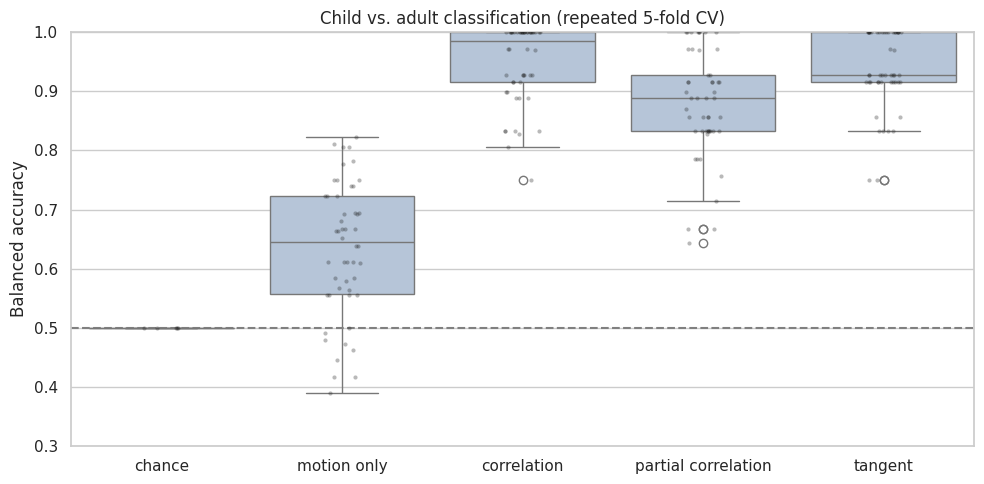

In [35]:
res_df = pd.concat([pd.DataFrame({"method": k, "balanced_accuracy": v}) for k, v in results.items()])
plot_order = ["chance", "motion only", "correlation", "partial correlation", "tangent"]

plt.figure(figsize=(10, 5))
sns.boxplot(data=res_df, x="method", y="balanced_accuracy", order=plot_order, color="lightsteelblue")
sns.stripplot(data=res_df, x="method", y="balanced_accuracy", order=plot_order, color="k", alpha=0.3, size=3)
plt.axhline(0.5, ls="--", c="gray")
plt.ylim(0.3, 1.0)
plt.title("Child vs. adult classification (repeated 5-fold CV)")
plt.ylabel("Balanced accuracy"); plt.xlabel("")
plt.tight_layout(); plt.show()

Where does the best model make mistakes?

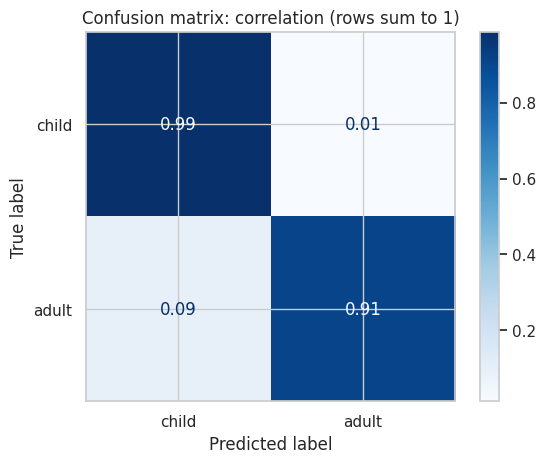

In [36]:
best = max(["correlation", "partial correlation", "tangent"], key=lambda k: results[k].mean())
cm = confusions[best]
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=["child", "adult"]).plot(
    cmap="Blues", values_format=".2f")
plt.title(f"Confusion matrix: {best} (rows sum to 1)")
plt.show()

The diagonal shows the share correctly identified in each group. Off-diagonal: e.g. "adults mistaken for children." If errors are uneven, it shows which group is harder to recognise.

**Which connections does the model rely on?**

Positive weight = stronger in adults; negative = stronger in children


,region_A,network_A,region_B,network_B,weight
401,Broca,Language,V ACC,Salience,-0.132
503,Cereb,Cereb,Occ post,Occ post,0.132
664,R Ins,Cing-Ins,L Ins,Cing-Ins,0.131
510,Cereb,Cereb,L Par,L V Att,0.130
350,R STS,Temporal,L STS,Temporal,0.121
402,Broca,Language,R A Ins,Salience,-0.120
132,L Front pol,L V Att,R Post Temp,R V Att,0.119
362,L TPJ,Language,R Par,R V Att,-0.116
307,L STS,Temporal,Occ post,Occ post,0.113
188,L LOC,Vis Sec,L IPS,D Att,-0.113


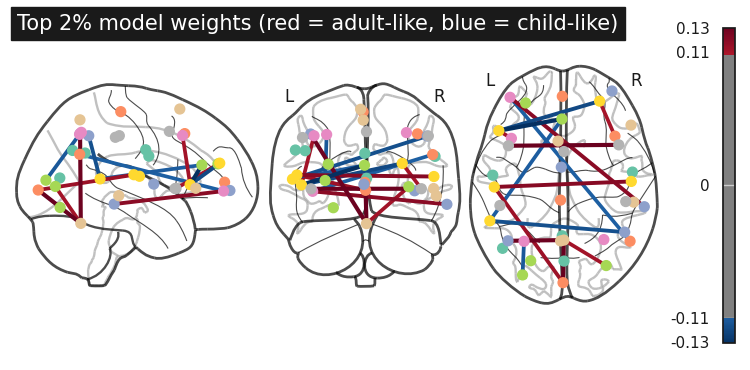

In [37]:
conn = ConnectivityMeasure(kind="correlation", vectorize=True, discard_diagonal=True,
                           standardize="zscore_sample")
X_all = conn.fit_transform(time_series)
model = make_pipeline(StandardScaler(),
                      LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)).fit(X_all, y)

weights = model[-1].coef_.ravel()                 # one weight per connection
rows, cols = np.tril_indices(len(labels), k=-1)   # matches nilearn's vector order

top = pd.DataFrame({
    "region_A": labels[rows], "network_A": networks[rows],
    "region_B": labels[cols], "network_B": networks[cols],
    "weight": weights,
}).reindex(np.argsort(-np.abs(weights)))
print("Positive weight = stronger in adults; negative = stronger in children")
display(top.head(10).round(3))

w_mat = np.zeros((len(labels), len(labels)))
w_mat[rows, cols] = weights
w_mat = w_mat + w_mat.T
plotting.plot_connectome(w_mat, coords, edge_threshold="98%", edge_cmap="RdBu_r",
                         title="Top 2% model weights (red = adult-like, blue = child-like)")
plt.show()

This cell is only for interpretation, not for scoring accuracy (Cell 6.2 already did that properly). Correlation weights map directly onto real connections, which is easier to explain than tangent weights. Day 3 checks whether these top connections are stable across folds.